<a href="https://colab.research.google.com/github/gioftaka/Modelagem-Termica-e-Processamento-de-Sinal-de-Termopar-MI/blob/05%2F11/Trab_Final_Mat_Comp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Introdução

Os termopares industriais são sensores utilizados para medir temperatura em diferentes processos. Seu funcionamento baseia-se no efeito Seebeck, no qual a diferença de temperatura entre dois condutores de materiais distintos gera uma tensão elétrica.

Em aplicações industriais, são comuns os termopares com isolação mineral (MI), constituídos por fios condutores envolvidos por óxido de magnésio (MgO) e protegidos por uma bainha metálica. Essa estrutura oferece proteção mecânica e isolamento elétrico, mas também influencia a velocidade de resposta do sensor às variações de temperatura.

Neste trabalho, será estudada a transferência de calor em termopares com bainha de aço inoxidável AISI 316L e região interna representada pelas propriedades térmicas do MgO. O objetivo é comparar cabos de 3 mm e 6 mm de diâmetro e analisar como as dimensões de suas camadas influenciam a resposta térmica, utilizando o método das diferenças finitas para resolver numericamente a equação do calor.

Além da análise térmica, será estudada a aplicação de filtros digitais ao sinal do termopar, com o objetivo de reduzir possíveis ruídos e interferências eletromagnéticas presentes nas medições. Dessa forma, o trabalho também busca avaliar como o processamento digital pode contribuir para melhorar a qualidade do sinal de temperatura.

# 2. Modelagem matemática

O termopar será representado por um modelo unidimensional, dividido em duas regiões: a bainha de aço inoxidável e a região interna equivalente, representada pelo MgO.

A transferência de calor será descrita pela equação:

$$
\rho c_p\frac{\partial T}{\partial t}
=
k\frac{\partial^2 T}{\partial x^2}
$$

Em que \(T\) é a temperatura, \(t\) é o tempo, \(x\) é a posição, \(k\) é a condutividade térmica, \(\rho\) é a massa específica e \(c_p\) é o calor específico.

## 2.1. Dimensões e propriedades

Serão analisados dois cabos com dimensões baseadas em especificações comerciais de termopares MI:

| Parâmetro | Cabo 3 mm | Cabo 6 mm |
|---|---:|---:|
| Raio externo | 1,50 mm | 3,00 mm |
| Espessura da bainha | 0,30 mm | 0,60 mm |
| Região interna equivalente | 1,20 mm | 2,40 mm |

A região interna é uma simplificação do modelo, pois o cabo real também possui fios condutores envolvidos pelo MgO.

As propriedades térmicas adotadas são:

| Propriedade | Aço AISI 316L | MgO |
|---|---:|---:|
| Condutividade térmica (W/m·K) | 15,0 | 2,36 |
| Massa específica (kg/m³) | 8000 | 2000 |
| Calor específico (J/kg·K) | 500 | 900 |

Para simplificar a simulação, essas propriedades serão consideradas constantes.

## 2.2. Hipóteses e condições de contorno

O modelo considera condução de calor em uma única direção, materiais homogêneos e ausência de geração interna de calor.

Inicialmente, todo o cabo estará a 25 °C. Em seguida, sua superfície externa será submetida à temperatura constante de 150 °C.

As condições são:

- **Temperatura inicial:** 25 °C em todo o domínio;
- **Superfície externa:** temperatura constante de 150 °C;
- **Interface entre os materiais:** continuidade da temperatura e do fluxo de calor;
- **Extremidade interna:** fluxo de calor nulo.

Essas condições permitem simular a propagação do calor através das duas regiões e comparar a resposta térmica dos cabos.

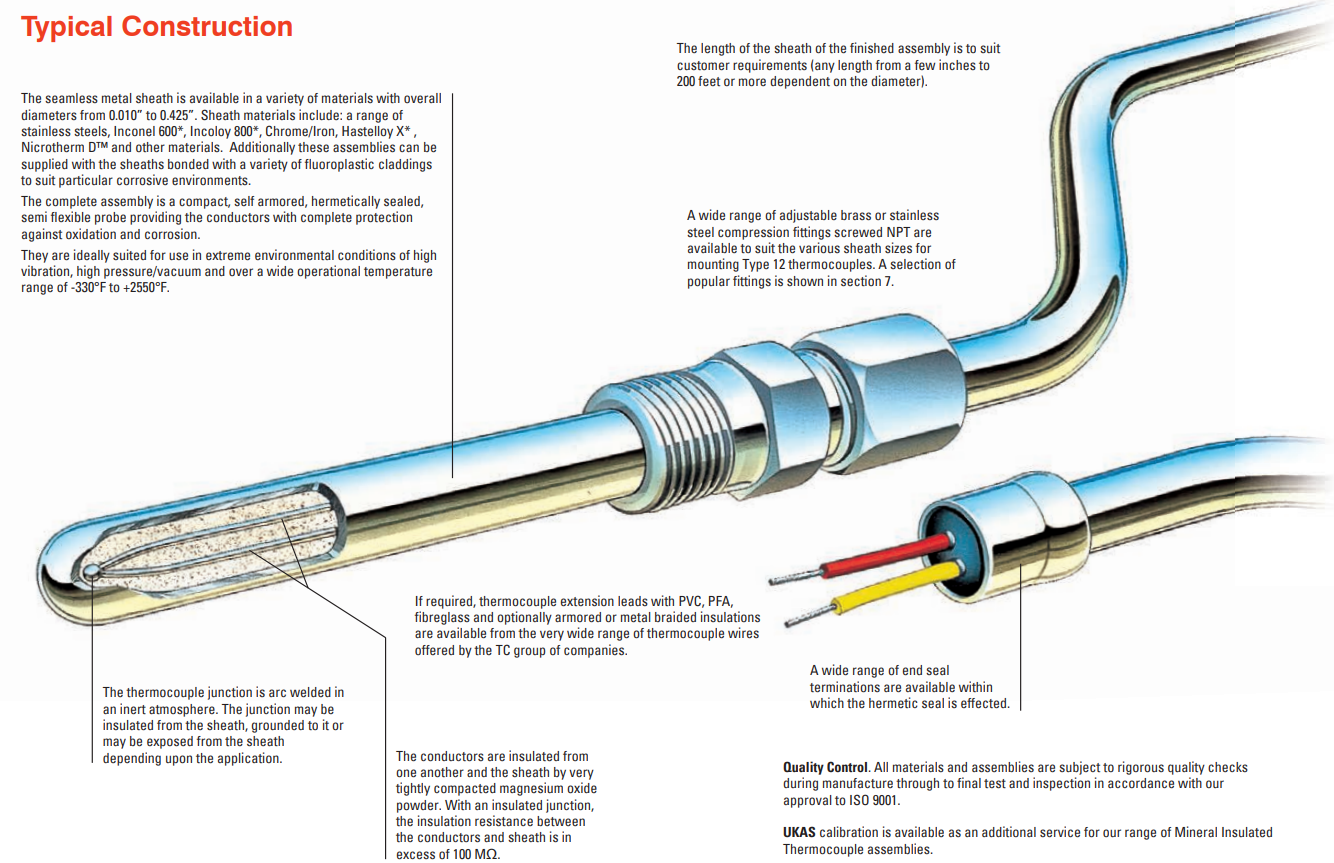

3 mm: tempo de resposta = 0.5974 s
6 mm: tempo de resposta = 2.3894 s


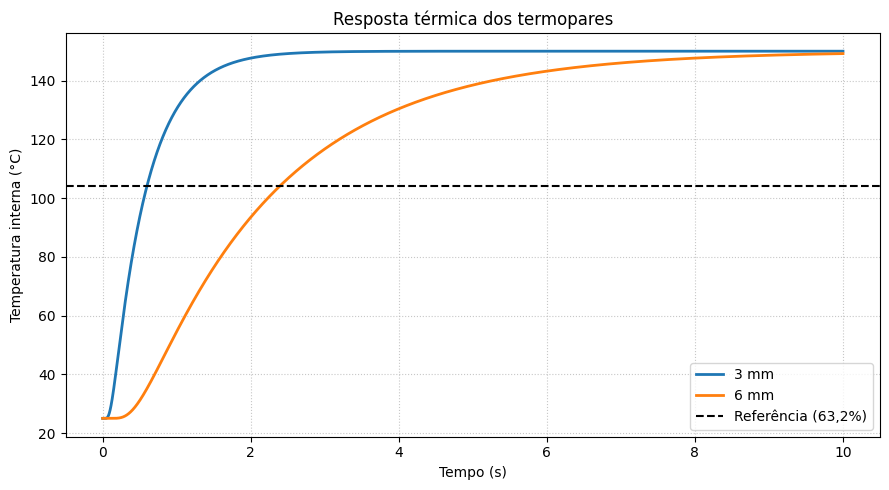

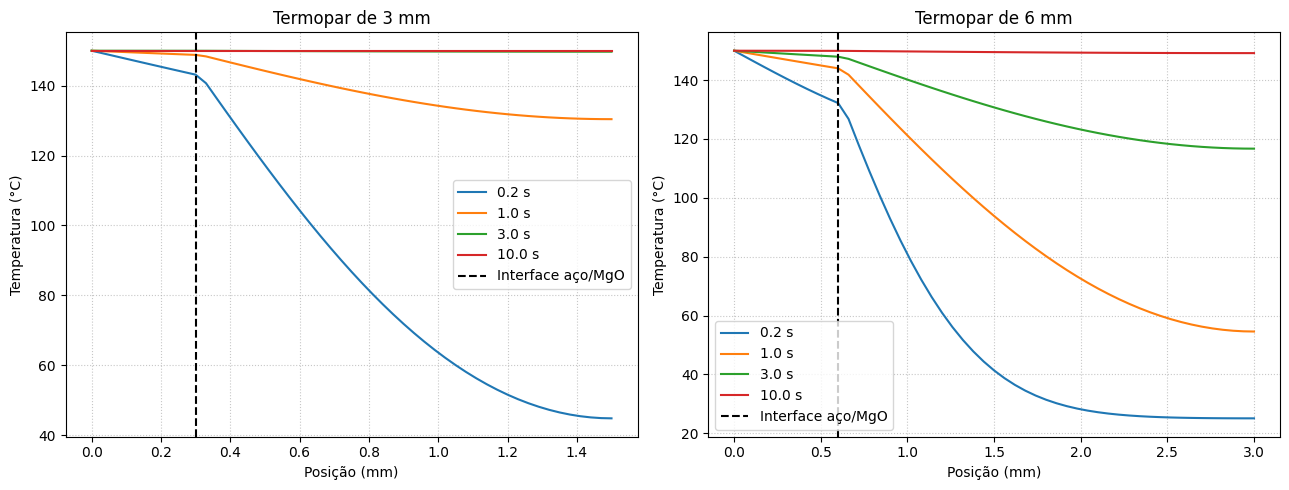

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros físicos

# Propriedades do aço AISI 316L
k_aco = 15.0
rho_aco = 8000.0
cp_aco = 500.0

# Propriedades do MgO
k_mgo = 2.36
rho_mgo = 2000.0
cp_mgo = 900.0

# Geometria dos dois termopares (metros)
cabos = {
    "3 mm": {"L_aco": 0.00030, "L_mgo": 0.00120},
    "6 mm": {"L_aco": 0.00060, "L_mgo": 0.00240}
}

# Condições da simulação
T_inicial = 25.0
T_externa = 150.0
tempo_simulacao = 10.0
Nx = 51


# 2. Simulação pelo método das diferenças finitas

def simular_termopar(L_aco, L_mgo):

    L = L_aco + L_mgo

    # Malha espacial
    x = np.linspace(0, L, Nx)
    dx = x[1] - x[0]

    # Propriedades em cada região
    k = np.where(x <= L_aco + 1e-12, k_aco, k_mgo)
    rho = np.where(x <= L_aco + 1e-12, rho_aco, rho_mgo)
    cp = np.where(x <= L_aco + 1e-12, cp_aco, cp_mgo)

    # Condutividade entre os pontos da malha
    k_face = 2 * k[:-1] * k[1:] / (k[:-1] + k[1:])

    # Passo temporal para estabilidade
    dt_limite = 0.4 * np.min(rho * cp) * dx**2 / np.max(k)
    Nt = int(np.ceil(tempo_simulacao / dt_limite))
    dt = tempo_simulacao / Nt

    # Temperatura inicial e condição externa
    u = np.ones(Nx) * T_inicial
    u[0] = T_externa

    # Histórico da temperatura interna
    historico = np.zeros(Nt + 1)
    historico[0] = u[-1]

    # Perfis de temperatura em instantes escolhidos
    instantes = [0.2, 1.0, 3.0, 10.0]
    curvas = {}

    # 3. Método FTCS
    for n in range(1, Nt + 1):

        u_novo = u.copy()

        fluxo_direita = k_face[1:] * (u[2:] - u[1:-1])
        fluxo_esquerda = k_face[:-1] * (u[1:-1] - u[:-2])

        u_novo[1:-1] = u[1:-1] + (
            dt / (rho[1:-1] * cp[1:-1] * dx**2)
        ) * (fluxo_direita - fluxo_esquerda)

        # Superfície externa a 150 °C
        u_novo[0] = T_externa

        # Fluxo nulo na extremidade interna
        u_novo[-1] = u[-1] + (
            2 * dt * k_face[-1] * (u[-2] - u[-1])
            / (rho[-1] * cp[-1] * dx**2)
        )

        u = u_novo
        historico[n] = u[-1]

        # Armazena os perfis nos instantes escolhidos
        for instante in instantes:
            if instante not in curvas and n * dt >= instante:
                curvas[instante] = u.copy()

    tempo = np.linspace(0, tempo_simulacao, Nt + 1)

    return x, tempo, historico, curvas


# 4. Execução das simulações

resultados = {}

for nome, dimensoes in cabos.items():

    resultados[nome] = simular_termopar(
        dimensoes["L_aco"],
        dimensoes["L_mgo"]
    )


# 5. Cálculo do tempo de resposta (63,2%)

T_referencia = T_inicial + 0.632 * (T_externa - T_inicial)

tempos_resposta = {}

for nome, resultado in resultados.items():

    x, tempo, historico, curvas = resultado

    indices = np.where(historico >= T_referencia)[0]

    if len(indices) > 0:
        i = indices[0]

        # Interpolação para estimar o instante
        t_resposta = np.interp(
            T_referencia,
            historico[i-1:i+1],
            tempo[i-1:i+1]
        )

        tempos_resposta[nome] = t_resposta

        print(f"{nome}: tempo de resposta = {t_resposta:.4f} s")

    else:
        tempos_resposta[nome] = None
        print(f"{nome}: temperatura de referência não atingida")


# 6. Gráfico da resposta térmica

plt.figure(figsize=(9, 5))

for nome, resultado in resultados.items():

    x, tempo, historico, curvas = resultado

    plt.plot(tempo, historico, linewidth=2, label=nome)

plt.axhline(
    T_referencia,
    color="black",
    linestyle="--",
    label="Referência (63,2%)"
)

plt.title("Resposta térmica dos termopares")
plt.xlabel("Tempo (s)")
plt.ylabel("Temperatura interna (°C)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.show()


# 7. Distribuição de temperatura no cabo

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

for eixo, (nome, resultado) in zip(eixos, resultados.items()):

    x, tempo, historico, curvas = resultado

    for instante, temperatura in curvas.items():

        eixo.plot(
            x * 1000,
            temperatura,
            label=f"{instante:.1f} s"
        )

    # Identifica a interface aço/MgO
    eixo.axvline(
        cabos[nome]["L_aco"] * 1000,
        color="black",
        linestyle="--",
        label="Interface aço/MgO"
    )

    eixo.set_title(f"Termopar de {nome}")
    eixo.set_xlabel("Posição (mm)")
    eixo.set_ylabel("Temperatura (°C)")
    eixo.legend()
    eixo.grid(True, linestyle=":", alpha=0.7)

plt.tight_layout()
plt.show()


### Solução Analítica e Série de Fourier

A solução analítica da equação do calor pode ser construída pela soma de uma parcela estacionária $v(x)$ e uma parcela transiente $w(x,t)$.

Para o modelo considerado, a superfície externa do termopar é submetida a uma temperatura constante de $150\,^\circ\text{C}$, enquanto a extremidade interna apresenta condição de fluxo térmico nulo. Como não há geração interna de calor, a distribuição de temperatura no estado estacionário é uniforme:

$
v(x)=150
$

A condição inicial estabelece que todo o domínio se encontra inicialmente à temperatura ambiente:

$
f(x)=25
$

Dessa forma, a diferença entre a condição inicial e o estado estacionário é:

$
f(x)-v(x)=25-150=-125
$

Para um domínio homogêneo, considerando as condições de contorno de temperatura fixa em uma extremidade e fluxo nulo na outra, a solução transiente pode ser representada por uma série de Fourier:

$
w(x,t)=
-\sum_{n=0}^{\infty}
\frac{500}{(2n+1)\pi}
\sin\left(\frac{(n+\frac12)\pi x}{L}\right)
e^{-\alpha\left(\frac{(n+\frac12)\pi}{L}\right)^2t}
$

Entretanto, o modelo numérico desenvolvido neste trabalho considera duas regiões com propriedades térmicas distintas: a bainha de aço inoxidável 316L e o preenchimento de MgO compactado. Portanto, a expressão apresentada para o domínio homogêneo não corresponde à solução analítica exata do sistema estudado, pois esta exigiria considerar as diferentes difusividades térmicas e as condições de continuidade de temperatura e fluxo de calor na interface entre os materiais.

Assim, a solução numérica pelo método das diferenças finitas (FTCS) é utilizada para representar a propagação térmica no domínio composto pelos dois materiais.

3 mm - Erro máximo: 0.004002 °C
6 mm - Erro máximo: 0.008757 °C


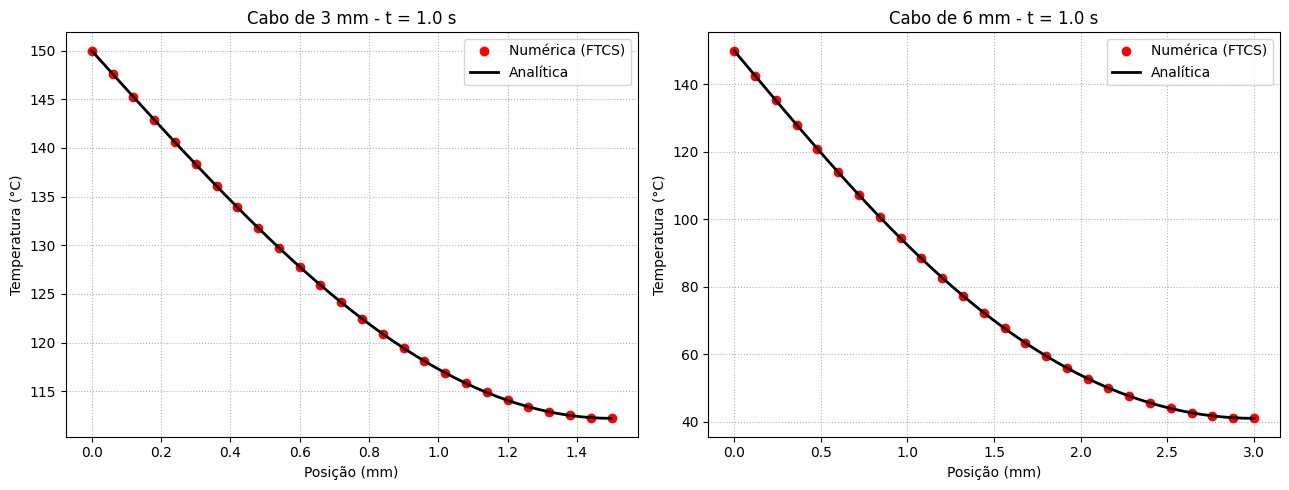

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros do modelo homogêneo de referência

k = 2.36
rho = 2000.0
cp = 900.0
alpha = k / (rho * cp)

cabos = {"3 mm": 0.0015, "6 mm": 0.0030}

T_inicial = 25.0
T_externa = 150.0
T_max = 1.0
Nx = 51

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

# 2. Simulação para cada comprimento

for eixo, (nome, L) in zip(eixos, cabos.items()):

    x = np.linspace(0, L, Nx)
    dx = x[1] - x[0]

    dt_limite = 0.2 * dx**2 / alpha
    Nt = int(np.ceil(T_max / dt_limite))
    dt = T_max / Nt
    F = alpha * dt / dx**2

    # Solução numérica FTCS
    u_num = np.ones(Nx) * T_inicial
    u_num[0] = T_externa

    for n in range(Nt):

        u_novo = u_num.copy()

        u_novo[1:-1] = u_num[1:-1] + F * (
            u_num[2:] - 2*u_num[1:-1] + u_num[:-2]
        )

        # Condições de contorno
        u_novo[0] = T_externa
        u_novo[-1] = u_num[-1] + 2*F*(
            u_num[-2] - u_num[-1]
        )

        u_num = u_novo

    # 3. Solução analítica por série de Fourier
    u_ana = np.ones(Nx) * T_externa

    for n in range(100):

        Cn = -500.0 / ((2*n + 1) * np.pi)

        u_ana += Cn * np.sin(
            (n + 0.5) * np.pi * x / L
        ) * np.exp(
            -alpha * ((n + 0.5)*np.pi/L)**2 * T_max
        )

    # 4. Comparação dos resultados
    erro = np.max(np.abs(u_num - u_ana))
    print(f"{nome} - Erro máximo: {erro:.6f} °C")

    eixo.plot(
        x * 1000, u_num, 'ro',
        markevery=2, label="Numérica (FTCS)"
    )

    eixo.plot(
        x * 1000, u_ana, 'k-',
        linewidth=2, label="Analítica"
    )

    eixo.set_title(f"Cabo de {nome} - t = {T_max} s")
    eixo.set_xlabel("Posição (mm)")
    eixo.set_ylabel("Temperatura (°C)")
    eixo.legend()
    eixo.grid(True, linestyle=":")

plt.tight_layout()
plt.show()


### Análise da Influência das Dimensões na Resposta Térmica do Sensor

Após a simulação da propagação de calor, será analisada a influência das dimensões do termopar em sua resposta térmica.

Inicialmente, serão comparados cabos de 3 mm e 6 mm de diâmetro, mantendo as mesmas propriedades térmicas do aço inoxidável AISI 316L e do MgO. Essa comparação permitirá avaliar como o tamanho do sensor influencia o tempo necessário para o aquecimento de sua região interna.

Posteriormente, será investigada a influência da espessura da bainha metálica e da extensão da região interna equivalente, variando essas dimensões individualmente para observar seus efeitos na propagação do calor.

As simulações serão realizadas pelo método das diferenças finitas (FTCS), permitindo comparar a evolução da temperatura e os tempos de resposta dos diferentes modelos.


Bainha: 0.30 mm
Região interna: 1.20 mm
Tempo de resposta: 0.5974 s

Bainha: 0.36 mm
Região interna: 1.14 mm
Tempo de resposta: 0.5558 s

Bainha: 0.42 mm
Região interna: 1.08 mm
Tempo de resposta: 0.5172 s


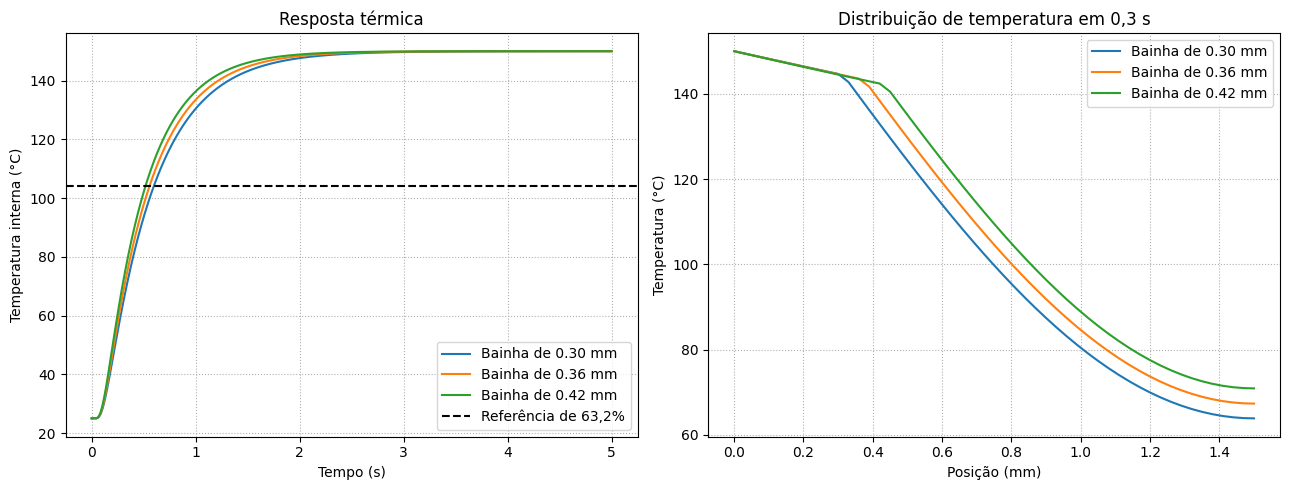

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros físicos

L = 0.00150               # Raio externo do cabo de 3 mm
T_max = 5.0

# Aço AISI 316L
k_aco = 15.0
rho_aco = 8000.0
cp_aco = 500.0

# MgO compactado
k_mgo = 2.36
rho_mgo = 2000.0
cp_mgo = 900.0

# Espessuras da bainha a serem comparadas
espessuras = [0.00030, 0.00036, 0.00042]

# 2. Malha espacial

Nx = 51
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]

# Passo temporal estável para todos os casos
dt_limite = 0.4 * min(
    rho_aco * cp_aco, rho_mgo * cp_mgo
) * dx**2 / max(k_aco, k_mgo)

Nt = int(np.ceil(T_max / dt_limite))
dt = T_max / Nt
tempo = np.linspace(0, T_max, Nt + 1)


# 3. Simulação pelo método FTCS

def simular_termopar(L_aco):

    # Propriedades de cada região
    k = np.where(x <= L_aco + 1e-12, k_aco, k_mgo)
    rho = np.where(x <= L_aco + 1e-12, rho_aco, rho_mgo)
    cp = np.where(x <= L_aco + 1e-12, cp_aco, cp_mgo)

    # Condutividade entre os pontos
    k_face = 2 * k[:-1] * k[1:] / (k[:-1] + k[1:])

    # Temperatura inicial
    u = np.ones(Nx) * 25.0
    u[0] = 150.0

    historico = np.zeros(Nt + 1)
    historico[0] = u[-1]

    perfil = None
    tempo_perfil = 0.3

    for n in range(1, Nt + 1):

        u_novo = u.copy()

        fluxo_direita = k_face[1:] * (u[2:] - u[1:-1])
        fluxo_esquerda = k_face[:-1] * (u[1:-1] - u[:-2])

        u_novo[1:-1] = u[1:-1] + (
            dt / (rho[1:-1] * cp[1:-1] * dx**2)
        ) * (fluxo_direita - fluxo_esquerda)

        # Temperatura externa constante
        u_novo[0] = 150.0

        # Fluxo nulo na extremidade interna
        u_novo[-1] = u[-1] + (
            2 * dt * k_face[-1] * (u[-2] - u[-1])
            / (rho[-1] * cp[-1] * dx**2)
        )

        u = u_novo
        historico[n] = u[-1]

        if perfil is None and tempo[n] >= tempo_perfil:
            perfil = u.copy()

    return historico, perfil


# 4. Comparação das espessuras

resultados = {}

T_referencia = 25.0 + 0.632 * (150.0 - 25.0)

for espessura in espessuras:

    historico, perfil = simular_termopar(espessura)

    # Tempo para atingir 63,2% da variação
    indices = np.where(historico >= T_referencia)[0]

    if len(indices) > 0:
        i = indices[0]
        t_resposta = np.interp(
            T_referencia,
            historico[i-1:i+1],
            tempo[i-1:i+1]
        )
    else:
        t_resposta = None

    resultados[espessura] = (historico, perfil, t_resposta)

    print(f"\nBainha: {espessura*1000:.2f} mm")
    print(f"Região interna: {(L-espessura)*1000:.2f} mm")

    if t_resposta is not None:
        print(f"Tempo de resposta: {t_resposta:.4f} s")


# 5. Gráficos comparativos

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

for espessura, resultado in resultados.items():

    historico, perfil, t_resposta = resultado
    nome = f"Bainha de {espessura*1000:.2f} mm"

    # Evolução da temperatura interna
    eixos[0].plot(tempo, historico, label=nome)

    # Distribuição de temperatura em 0,3 s
    eixos[1].plot(x*1000, perfil, label=nome)

eixos[0].axhline(
    T_referencia, color="black", linestyle="--",
    label="Referência de 63,2%"
)

eixos[0].set_title("Resposta térmica")
eixos[0].set_xlabel("Tempo (s)")
eixos[0].set_ylabel("Temperatura interna (°C)")
eixos[0].legend()
eixos[0].grid(True, linestyle=":")

eixos[1].set_title("Distribuição de temperatura em 0,3 s")
eixos[1].set_xlabel("Posição (mm)")
eixos[1].set_ylabel("Temperatura (°C)")
eixos[1].legend()
eixos[1].grid(True, linestyle=":")

plt.tight_layout()
plt.show()


### Análise dos Resultados da Resposta Dinâmica

A simulação numérica permite analisar como as dimensões do termopar influenciam a propagação do calor e sua resposta térmica.

Na comparação entre os cabos de 3 mm e 6 mm, espera-se que o termopar de menor diâmetro apresente uma resposta mais rápida, pois o calor percorre uma distância menor até a região interna.

A análise das diferentes espessuras da bainha permite observar como a distribuição entre o aço inoxidável AISI 316L e a região interna equivalente de MgO influencia a evolução da temperatura, mesmo mantendo o diâmetro externo constante.

Assim, os resultados permitem avaliar a influência da geometria e da distribuição dos materiais no tempo de resposta térmica do sensor.

### Processamento Digital do Sinal e Redução de Ruídos

Após a análise térmica dos termopares, será estudada a aplicação de filtros digitais para reduzir interferências no sinal de temperatura.

Para simular essas interferências, serão adicionados ao sinal térmico um ruído periódico de 60 Hz, representando a rede elétrica, e um ruído branco, representando perturbações aleatórias.

A Transformada Discreta de Fourier (DFT) será utilizada para analisar as frequências presentes no sinal. Em seguida, será aplicado um filtro passa-baixas RC de primeira ordem, com frequência de corte de 5 Hz, para atenuar componentes de alta frequência.

Por fim, a Transformada Discreta de Fourier Inversa (IDFT) permitirá reconstruir o sinal filtrado e compará-lo com o sinal original e o sinal com ruído.

Frequência de amostragem: 199.55 Hz
Quantidade de amostras: 998


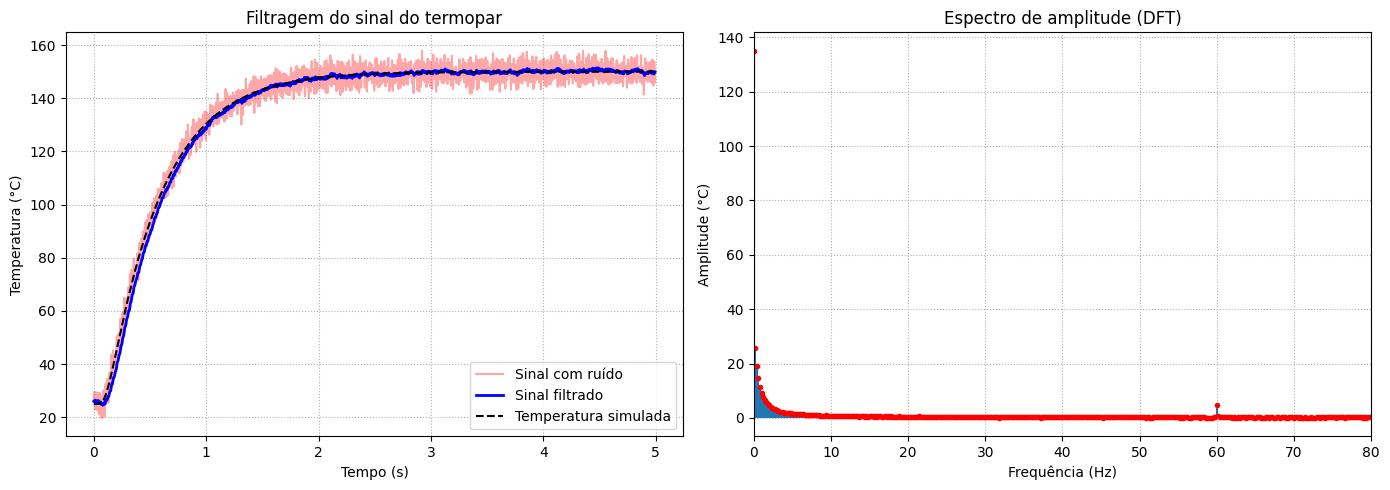


--- Avaliação da filtragem ---
Frequência analisada: 59.99 Hz
Amplitude antes: 4.8448 °C
Amplitude depois: 0.5196 °C
Redução da amplitude: 89.28%


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros do termopar de 3 mm

L_aco = 0.00030
L_mgo = 0.00120
L = L_aco + L_mgo

T_max = 5.0
Nx = 51

# Aço inoxidável AISI 316L
k_aco = 15.0
rho_aco = 8000.0
cp_aco = 500.0

# MgO compactado
k_mgo = 2.36
rho_mgo = 2000.0
cp_mgo = 900.0

# 2. Malha espacial

x = np.linspace(0, L, Nx)
dx = x[1] - x[0]

k = np.where(x <= L_aco + 1e-12, k_aco, k_mgo)
rho = np.where(x <= L_aco + 1e-12, rho_aco, rho_mgo)
cp = np.where(x <= L_aco + 1e-12, cp_aco, cp_mgo)

k_face = 2 * k[:-1] * k[1:] / (k[:-1] + k[1:])

# Passo temporal para estabilidade do FTCS
dt_limite = 0.4 * np.min(rho * cp) * dx**2 / np.max(k)
Nt = int(np.ceil(T_max / dt_limite))
dt = T_max / Nt

# 3. Frequência de amostragem

fs_desejada = 200.0
intervalo = max(1, round(1 / (fs_desejada * dt)))
fs = 1 / (intervalo * dt)

# 4. Simulação térmica pelo método FTCS

u = np.ones(Nx) * 25.0
u[0] = 150.0

historico = [u[-1]]
vetor_tempo = [0.0]

for n in range(1, Nt + 1):

    u_novo = u.copy()

    fluxo_direita = k_face[1:] * (u[2:] - u[1:-1])
    fluxo_esquerda = k_face[:-1] * (u[1:-1] - u[:-2])

    u_novo[1:-1] = u[1:-1] + (
        dt / (rho[1:-1] * cp[1:-1] * dx**2)
    ) * (fluxo_direita - fluxo_esquerda)

    # Condições de contorno
    u_novo[0] = 150.0

    u_novo[-1] = u[-1] + (
        2 * dt * k_face[-1] * (u[-2] - u[-1])
        / (rho[-1] * cp[-1] * dx**2)
    )

    u = u_novo

    # Amostragem da temperatura interna
    if n % intervalo == 0:
        historico.append(u[-1])
        vetor_tempo.append(n * dt)

historico = np.array(historico)
vetor_tempo = np.array(vetor_tempo)

N = len(historico)

print(f"Frequência de amostragem: {fs:.2f} Hz")
print(f"Quantidade de amostras: {N}")

# 5. Adição dos ruídos simulados

np.random.seed(42)

ruido_60Hz = 5.0 * np.sin(
    2 * np.pi * 60 * vetor_tempo
)

ruido_branco = np.random.normal(0, 1.5, N)

sinal_medido = historico + ruido_60Hz + ruido_branco

# 6. Transformada Discreta de Fourier (DFT)

X_original = np.fft.rfft(sinal_medido)

frequencias = np.fft.rfftfreq(N, d=1/fs)
amplitudes = 2 * np.abs(X_original) / N
amplitudes[0] /= 2

if N % 2 == 0:
    amplitudes[-1] /= 2

# 7. Filtro RC passa-baixas

f_corte = 5.0

# Extensão por reflexão
sinal_estendido = np.pad(
    sinal_medido, (N, N), mode="reflect"
)

N_ext = len(sinal_estendido)

# DFT do sinal estendido
X_ext = np.fft.fft(sinal_estendido)

freq_ext = np.fft.fftfreq(N_ext, d=1/fs)

# Função de transferência RC
H_rc = 1 / (1 + 1j * freq_ext / f_corte)

# Aplicação do filtro
X_filtrado = X_ext * H_rc

# 8. Transformada inversa (IDFT)

sinal_ext_filtrado = np.fft.ifft(X_filtrado).real

# Recuperação do trecho original
sinal_filtrado = sinal_ext_filtrado[N:2*N]

# 9. Gráficos comparativos

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Temperatura em função do tempo
ax1.plot(
    vetor_tempo, sinal_medido,
    color="red", alpha=0.35,
    label="Sinal com ruído"
)

ax1.plot(
    vetor_tempo, sinal_filtrado,
    color="blue", linewidth=2,
    label="Sinal filtrado"
)

ax1.plot(
    vetor_tempo, historico,
    "k--", linewidth=1.5,
    label="Temperatura simulada"
)

ax1.set_title("Filtragem do sinal do termopar")
ax1.set_xlabel("Tempo (s)")
ax1.set_ylabel("Temperatura (°C)")
ax1.legend()
ax1.grid(True, linestyle=":")

# Espectro de amplitude
ax2.stem(
    frequencias, amplitudes,
    basefmt=" ", markerfmt="r."
)

ax2.set_xlim(0, 80)
ax2.set_title("Espectro de amplitude (DFT)")
ax2.set_xlabel("Frequência (Hz)")
ax2.set_ylabel("Amplitude (°C)")
ax2.grid(True, linestyle=":")

plt.tight_layout()
plt.show()

# 10. Avaliação da redução do ruído de 60 Hz

X_depois = np.fft.rfft(sinal_filtrado)

indice_60 = np.argmin(np.abs(frequencias - 60))

amplitude_antes = 2 * abs(X_original[indice_60]) / N
amplitude_depois = 2 * abs(X_depois[indice_60]) / N

reducao = 100 * (
    1 - amplitude_depois / amplitude_antes
)

print("\n--- Avaliação da filtragem ---")
print(f"Frequência analisada: {frequencias[indice_60]:.2f} Hz")
print(f"Amplitude antes: {amplitude_antes:.4f} °C")
print(f"Amplitude depois: {amplitude_depois:.4f} °C")
print(f"Redução da amplitude: {reducao:.2f}%")


### Conclusão do Processamento Digital do Sinal

O processamento digital permitiu analisar os efeitos de interferências artificiais de 60 Hz e ruído branco sobre o sinal de temperatura simulado do termopar de 3 mm.

A Transformada Discreta de Fourier (DFT) foi utilizada para identificar as componentes de frequência, enquanto o filtro RC passa-baixas, com frequência de corte de 5 Hz, permitiu atenuar os ruídos de alta frequência.

Após a reconstrução do sinal pela Transformada Inversa de Fourier (IDFT), obteve-se uma resposta mais suave, demonstrando como a filtragem digital pode contribuir para melhorar a qualidade do sinal de temperatura.

## REFERÊNCIAS BIBLIOGRÁFICAS

APERAM. **Stainless Steel 316L: Technical Data Sheet**. Disponível em: https://www.aperam.com/sites/default/files/documents/FT_316L_en_web.pdf. Acesso em: 2 nov. 2026.

ALUTAL. **Catálogo técnico: Termopares de isolação mineral**. Disponível em: https://www.alutal.com.br/wp-content/uploads/2023/06/catalogotecnicoalutal_194.pdf. Acesso em: 2 nov. 2026.

INTERNATIONAL ELECTROTECHNICAL COMMISSION (IEC). **IEC 61515:2016: Mineral insulated metal-sheathed thermocouple cables and thermocouples**. Genebra: IEC, 2016.

KME ITALY S.p.A. **Instruction Manual: Mineral Insulated Cables MICO and Their Terminations**. Disponível em: https://www.kme.com/fileadmin/DOWNLOADCENTER/COPPER%20DIVISON/6._Mineral_Insulated_Cables/Ueberarbeitet_MICO_ohne_Register_10.2022/KME_Italy_SpA_-_Instruction_Manual_-_Mineral_Insulated_Cables_MCO_and_their_terminations_rev_04.pdf. Acesso em: 2 nov. 2026.

NATIONAL INSTITUTE OF STANDARDS AND TECHNOLOGY (NIST). **Structural Ceramics Database: Magnesium Oxide (MgO)**. Disponível em: https://srdata.nist.gov/CeramicDataPortal/Scd/Z00181. Acesso em: 2 nov. 2026.

SMITH, Steven W. **The Scientist and Engineer’s Guide to Digital Signal Processing**. 2. ed. California Technical Publishing, 1999. Disponível em: https://www.analog.com/en/resources/technical-books/scientist_engineers_guide.html. Acesso em: 2 nov. 2026.

YOKOGAWA. **TI 6B0A1-01E: Mineral Insulated Thermocouples**. Disponível em: https://web-material3.yokogawa.com/TI06B00A01-01EN.pdf. Acesso em: 2 nov. 2026.

TC MEASUREMENT AND CONTROL INC. *Mineral Insulated Thermocouples – Type 12*. [S. l.]: TC Inc., [s. d.]. Disponível em: https://www.tc-inc.com/downloads/Mineral-Insulated-Thermocouples-Type-12.pdf. Acesso em: 2 nov. 2026.

**MATERIAL DIDÁTICO DA DISCIPLINA.** Aulas de Matemática Computacional II: equação do calor, diferenças finitas, método FTCS, Transformada Discreta de Fourier e processamento de sinais. Material disponibilizado pelo docente.